Dataset loaded successfully!
Shape: (29531, 16)

Columns in dataset:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Features used:
['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3']

Input shape: (29531, 9)
Output shape: (29531,)

Data after cleaning: (13965, 9)

Training data: (11172, 9)
Testing data: (2793, 9)

Data scaling completed!

Random Forest model created!
XGBoost model created!
LightGBM model created!
Linear Regression model created!
Original MLP model created!
Improved MLP model created!

Training Random Forest...
Random Forest training completed!

Training XGBoost...
XGBoost training completed!

Training LightGBM...
LightGBM training completed!

Training Linear Regression...
Linear Regression training completed!

Training Original MLP...
Original MLP training completed!
Original MLP iterations: 101

Training Improved MLP...
Improved MLP training completed!
Improved MLP itera

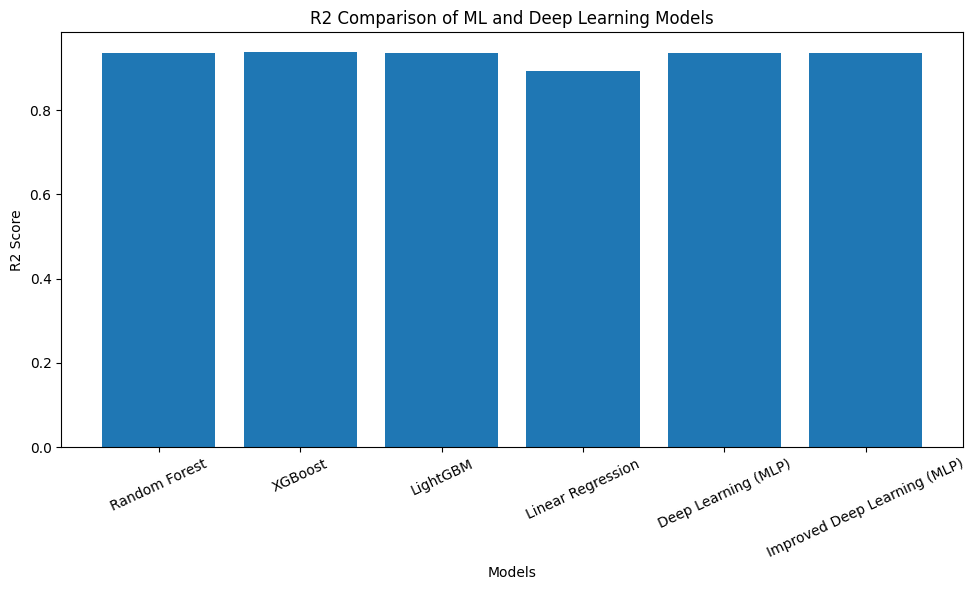

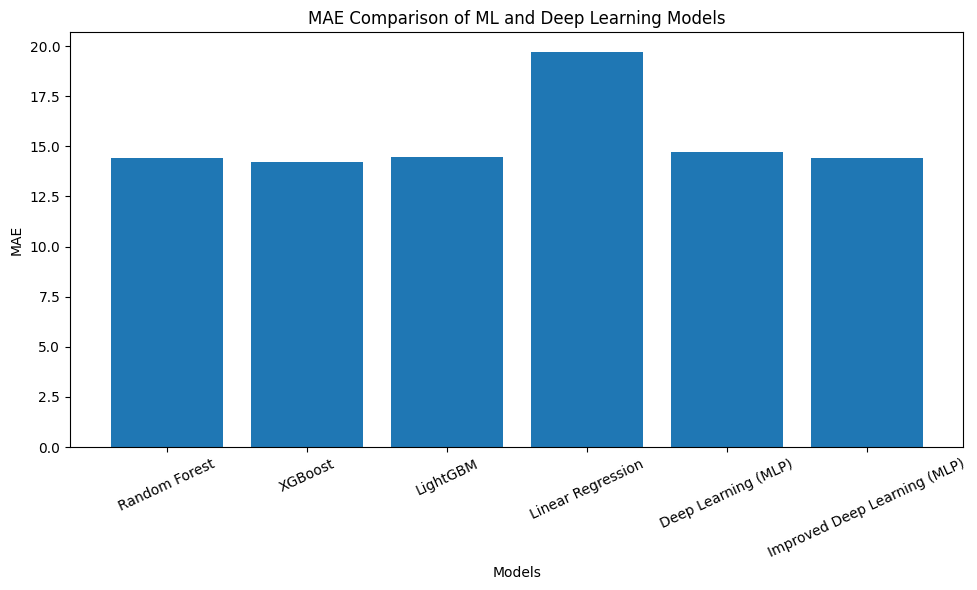

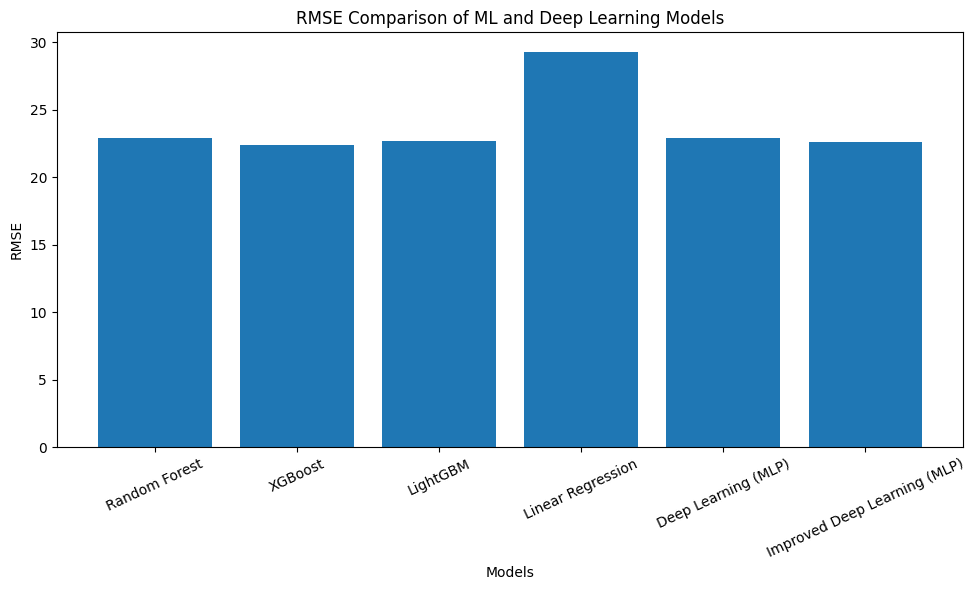

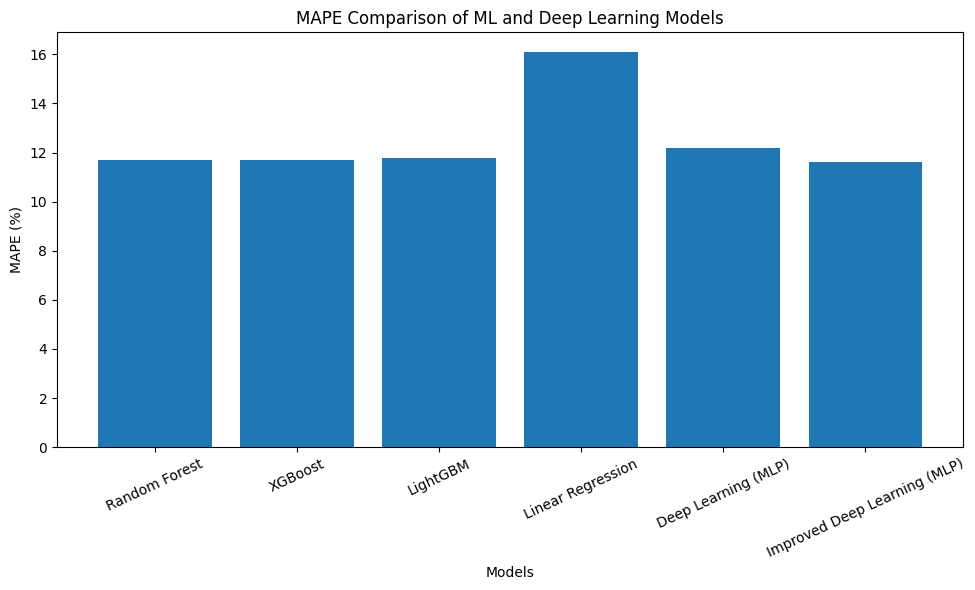

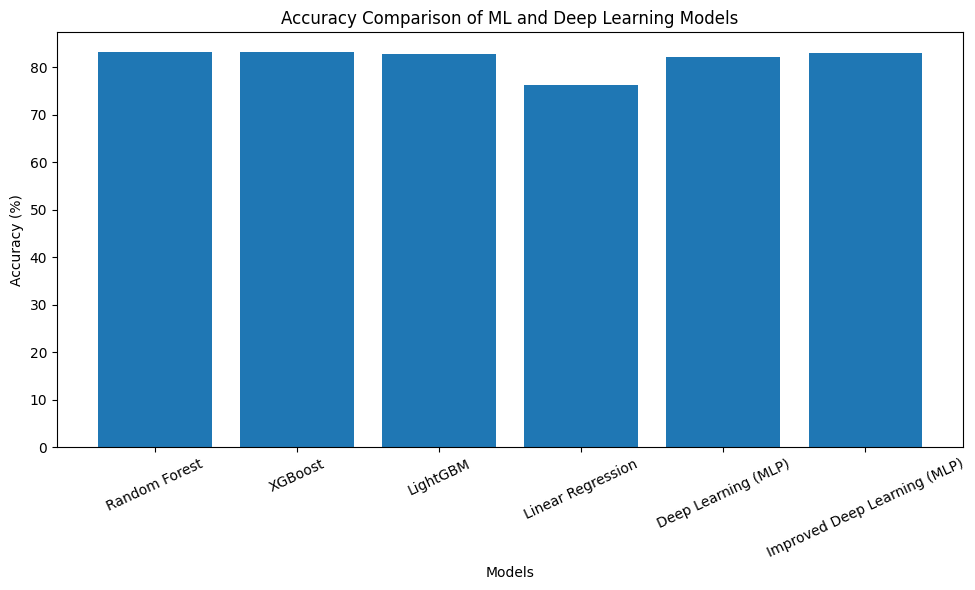

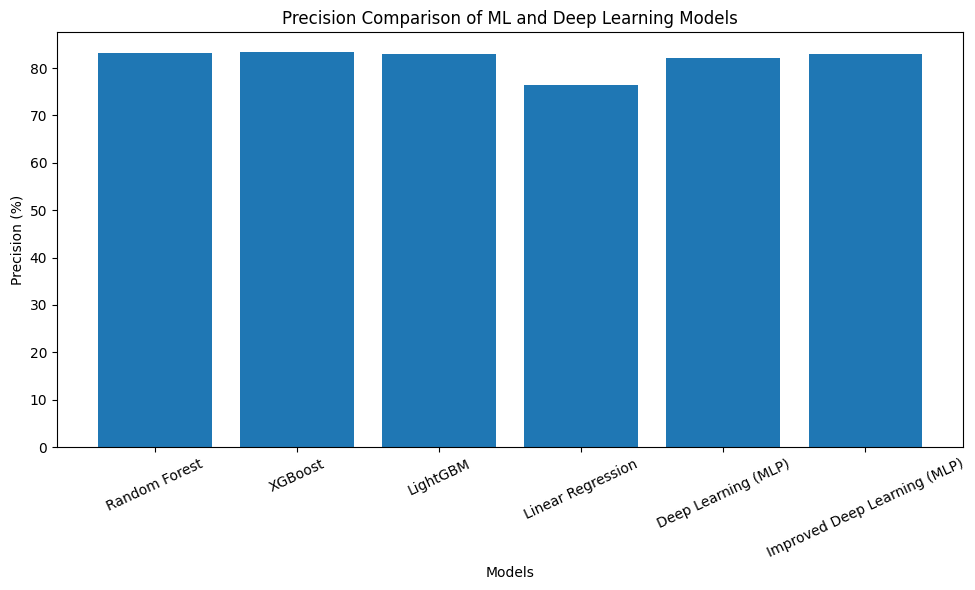

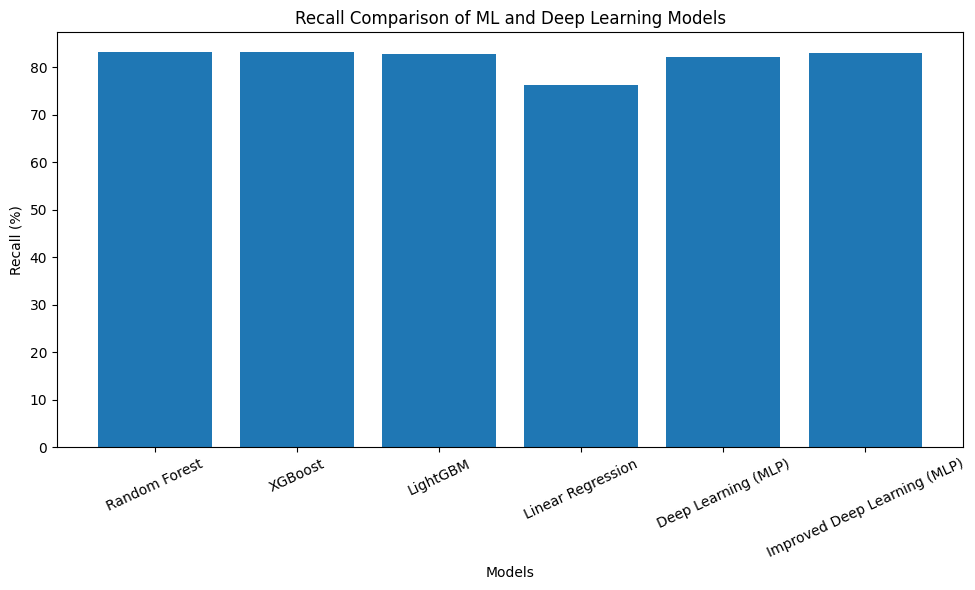

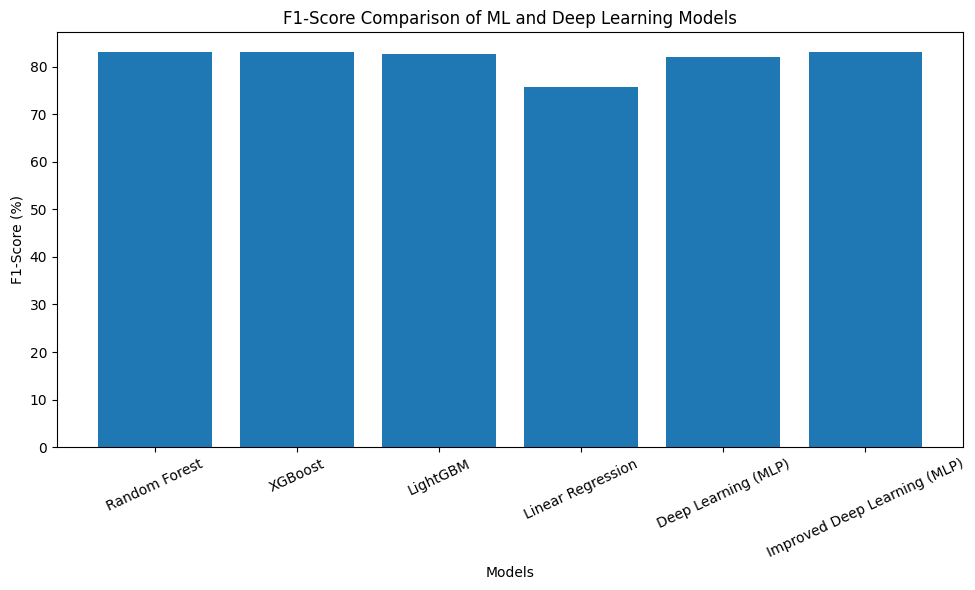

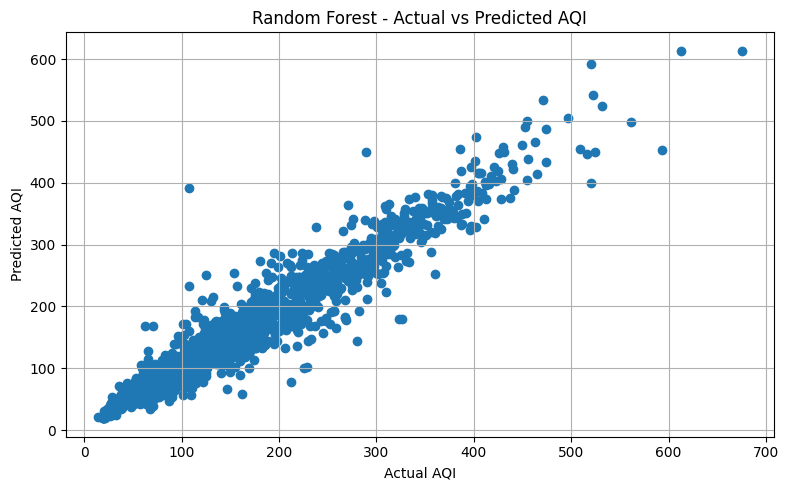

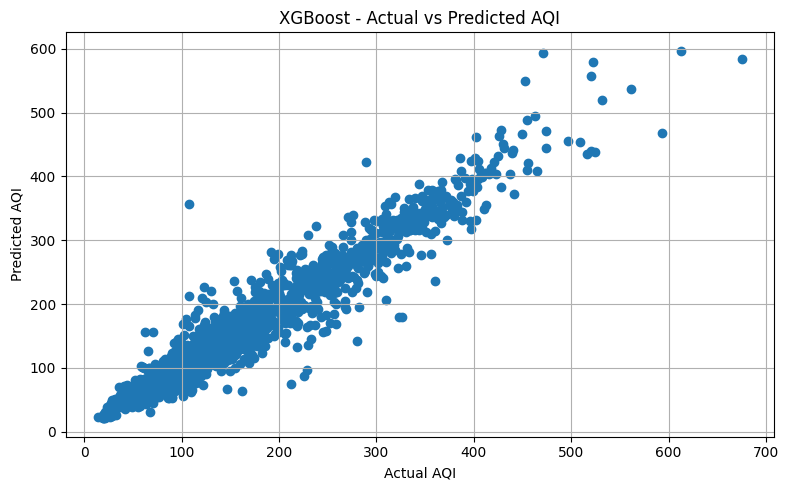

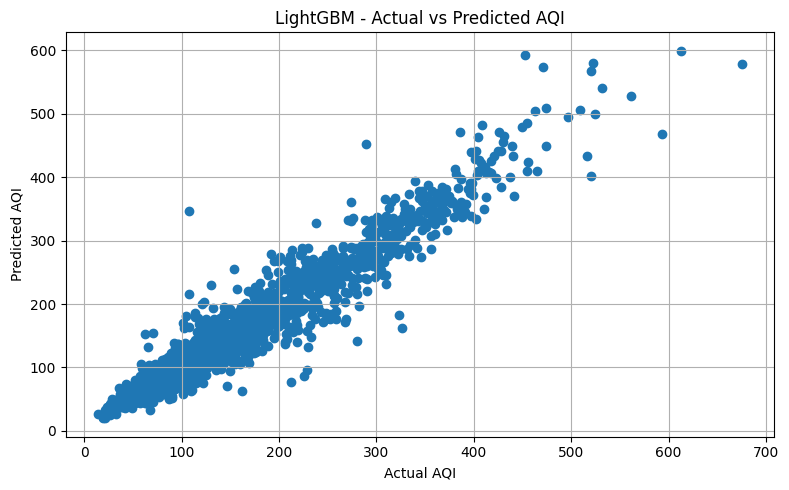

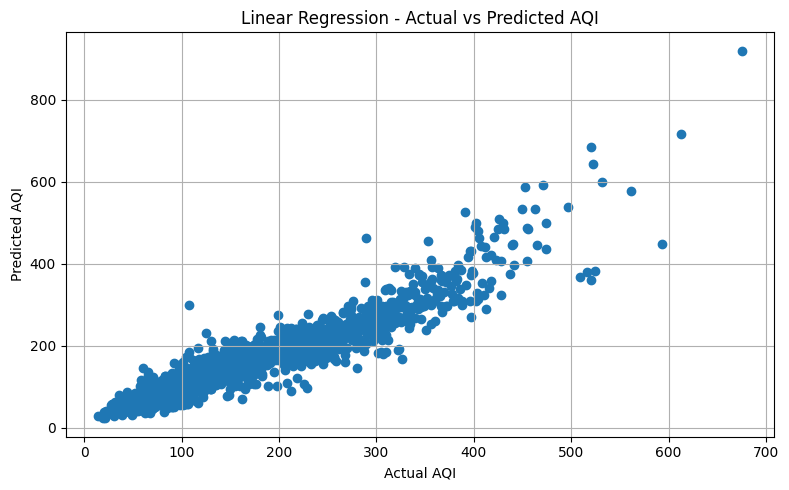

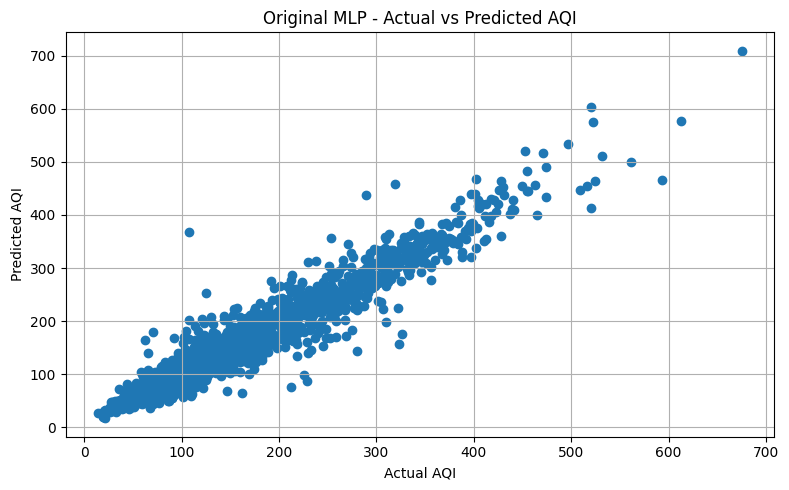

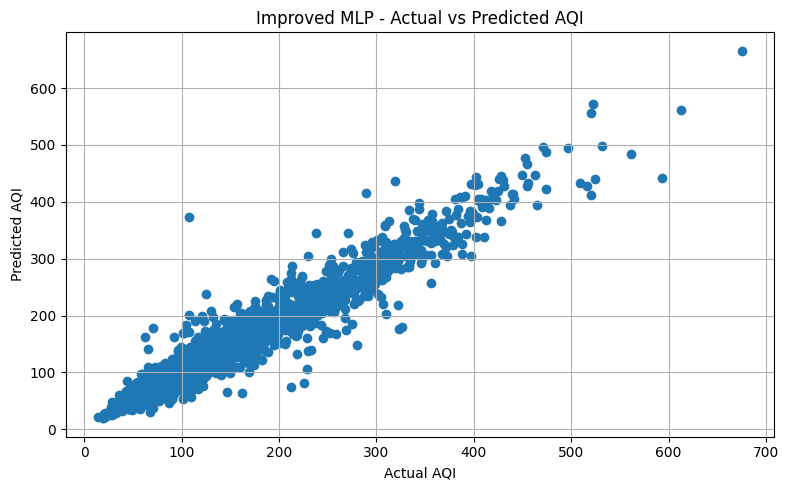



             RANDOM FOREST FEATURE IMPORTANCE
Feature  Importance
  PM2.5    0.730531
   PM10    0.195336
     CO    0.021582
     O3    0.012939
    NOx    0.010212
    NH3    0.007957
    NO2    0.007532
     NO    0.007115
    SO2    0.006798


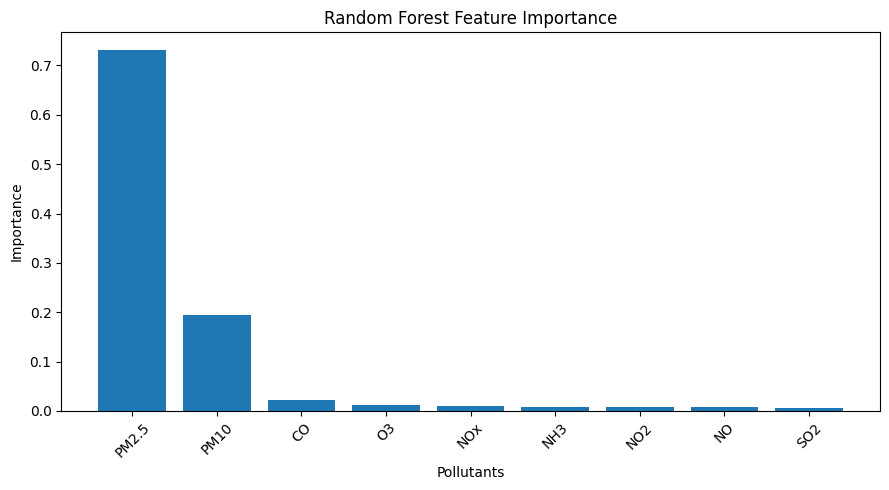

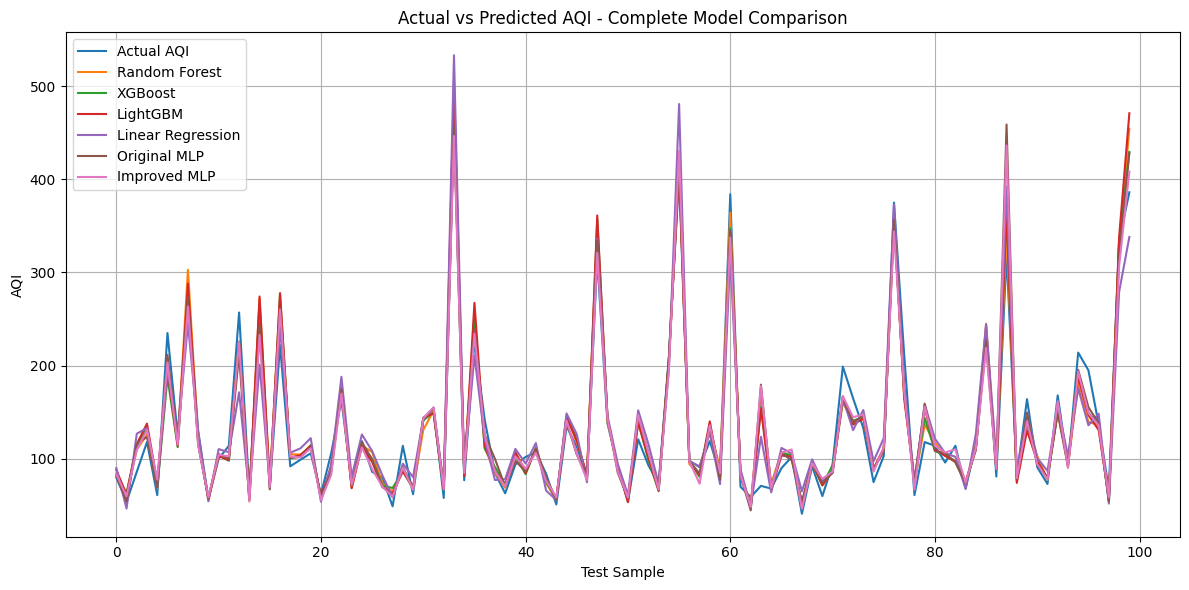

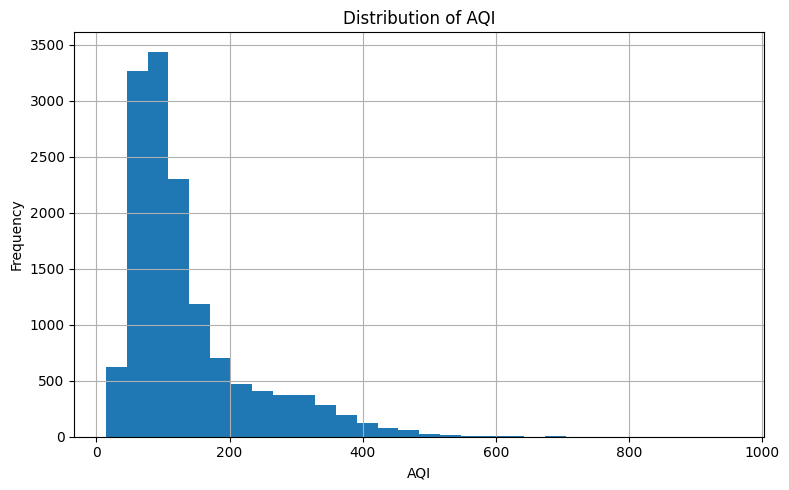




                         FINAL RESULTS
                       Model   MAE  RMSE     R2  MAPE (%)  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
               Random Forest 14.41 22.90 0.9350     11.69         83.17          83.25       83.17         83.08
                     XGBoost 14.23 22.38 0.9379     11.70         83.24          83.36       83.24         83.07
                    LightGBM 14.47 22.65 0.9364     11.76         82.89          82.99       82.89         82.71
           Linear Regression 19.70 29.26 0.8939     16.09         76.37          76.44       76.37         75.83
         Deep Learning (MLP) 14.72 22.88 0.9351     12.18         82.10          82.10       82.10         82.01
Improved Deep Learning (MLP) 14.44 22.63 0.9365     11.62         83.06          83.05       83.06         83.02

Project evaluation completed successfully!

Best model based on R2: XGBoost
Best model based on MAE: XGBoost
Best model based on RMSE: XGBoost
Best model based on F1-

In [ ]:
# ============================================================
# AQI PREDICTION USING MACHINE LEARNING AND DEEP LEARNING
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor


# ============================================================
# 1. LOAD DATASET
# ============================================================

df = pd.read_csv("air_quality.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)


# ============================================================
# 2. CLEAN COLUMN NAMES
# ============================================================

df.columns = df.columns.str.strip()

print("\nColumns in dataset:")
print(df.columns.tolist())


# ============================================================
# 3. SELECT FEATURES
# ============================================================

features = [
    "PM2.5",
    "PM10",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3"
]

# Keep only features present in the dataset
features = [f for f in features if f in df.columns]

if "AQI" not in df.columns:
    print("\nERROR: AQI column not found!")
    exit()

print("\nFeatures used:")
print(features)


# ============================================================
# 4. CREATE INPUT AND OUTPUT
# ============================================================

X = df[features]
y = df["AQI"]

print("\nInput shape:", X.shape)
print("Output shape:", y.shape)


# ============================================================
# 5. CONVERT DATA TO NUMERIC
# ============================================================

X = X.apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(y, errors="coerce")


# ============================================================
# 6. HANDLE MISSING AND INVALID VALUES
# ============================================================

data = pd.concat([X, y], axis=1)

data = data.replace([np.inf, -np.inf], np.nan)

data = data.dropna()

X = data[features]
y = data["AQI"]

print("\nData after cleaning:", X.shape)


# ============================================================
# 7. SPLIT DATA INTO TRAINING AND TESTING
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)


# ============================================================
# 8. SCALE DATA
# ============================================================

# Scaling is mainly useful for:
# Linear Regression
# Original MLP
# Improved MLP

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nData scaling completed!")


# ============================================================
# 9. CREATE MODELS
# ============================================================


# ------------------------------------------------------------
# MODEL 1 - RANDOM FOREST
# ------------------------------------------------------------

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

print("\nRandom Forest model created!")


# ------------------------------------------------------------
# MODEL 2 - XGBOOST
# ------------------------------------------------------------

xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

print("XGBoost model created!")


# ------------------------------------------------------------
# MODEL 3 - LIGHTGBM
# ------------------------------------------------------------

lgbm_model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

print("LightGBM model created!")


# ------------------------------------------------------------
# MODEL 4 - LINEAR REGRESSION
# ------------------------------------------------------------

lr_model = LinearRegression()

print("Linear Regression model created!")


# ============================================================
# MODEL 5 - ORIGINAL MLP
# MULTI-LAYER PERCEPTRON
# ============================================================

dl_model = MLPRegressor(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)

print("Original MLP model created!")


# ============================================================
# MODEL 6 - IMPROVED MLP
# ============================================================
#
# CHANGES FROM ORIGINAL MLP:
#
# Original:
# 128 -> 64 -> 32
#
# Improved:
# 256 -> 128 -> 64 -> 32
#
# Improvements:
# 1. Larger first hidden layer
# 2. Additional hidden layer
# 3. max_iter increased from 500 to 1000
# 4. validation_fraction increased from 0.10 to 0.15
# 5. n_iter_no_change = 30
#
# ============================================================

improved_dl_model = MLPRegressor(
    hidden_layer_sizes=(256, 128, 64, 32),  # IMPROVED
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=1000,                           # IMPROVED
    early_stopping=True,
    validation_fraction=0.15,                # IMPROVED
    n_iter_no_change=30,                     # IMPROVED
    random_state=42
)

print("Improved MLP model created!")


# ============================================================
# 10. TRAIN RANDOM FOREST
# ============================================================

print("\nTraining Random Forest...")

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


# ============================================================
# 11. TRAIN XGBOOST
# ============================================================

print("\nTraining XGBoost...")

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")


# ============================================================
# 12. TRAIN LIGHTGBM
# ============================================================

print("\nTraining LightGBM...")

lgbm_model.fit(X_train, y_train)

print("LightGBM training completed!")


# ============================================================
# 13. TRAIN LINEAR REGRESSION
# ============================================================

print("\nTraining Linear Regression...")

lr_model.fit(X_train_scaled, y_train)

print("Linear Regression training completed!")


# ============================================================
# 14. TRAIN ORIGINAL MLP
# ============================================================

print("\nTraining Original MLP...")

dl_model.fit(X_train_scaled, y_train)

print("Original MLP training completed!")

print("Original MLP iterations:", dl_model.n_iter_)


# ============================================================
# 15. TRAIN IMPROVED MLP
# ============================================================

print("\nTraining Improved MLP...")

improved_dl_model.fit(
    X_train_scaled,
    y_train
)

print("Improved MLP training completed!")

print(
    "Improved MLP iterations:",
    improved_dl_model.n_iter_
)


# ============================================================
# 16. MAKE PREDICTIONS
# ============================================================

print("\nMaking predictions...")

rf_pred = rf_model.predict(X_test)

xgb_pred = xgb_model.predict(X_test)

lgbm_pred = lgbm_model.predict(X_test)

lr_pred = lr_model.predict(X_test_scaled)

# Original MLP prediction
dl_pred = dl_model.predict(X_test_scaled)

# Improved MLP prediction
improved_dl_pred = improved_dl_model.predict(
    X_test_scaled
)

print("Predictions completed!")


# ============================================================
# 17. AQI CATEGORY FUNCTION
# ============================================================

def get_aqi_category(aqi):

    if aqi <= 50:
        return "Good"

    elif aqi <= 100:
        return "Satisfactory"

    elif aqi <= 200:
        return "Moderate"

    elif aqi <= 300:
        return "Poor"

    elif aqi <= 400:
        return "Very Poor"

    else:
        return "Severe"


# ============================================================
# 18. EVALUATION FUNCTION
# ============================================================

def evaluate_model(
    model_name,
    actual,
    predicted
):

    # --------------------------------------------------------
    # REGRESSION METRICS
    # --------------------------------------------------------

    # Mean Absolute Error
    mae = mean_absolute_error(
        actual,
        predicted
    )

    # Root Mean Squared Error
    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    # R2 Score
    r2 = r2_score(
        actual,
        predicted
    )

    # Mean Absolute Percentage Error
    non_zero = actual != 0

    mape = np.mean(
        np.abs(
            (
                actual[non_zero]
                - predicted[non_zero]
            )
            /
            actual[non_zero]
        )
    ) * 100

    # --------------------------------------------------------
    # CONVERT AQI TO CATEGORIES
    # --------------------------------------------------------

    actual_categories = actual.apply(
        get_aqi_category
    )

    predicted_categories = pd.Series(
        predicted,
        index=actual.index
    ).apply(
        get_aqi_category
    )

    # --------------------------------------------------------
    # CLASSIFICATION METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(
        actual_categories,
        predicted_categories
    )

    precision = precision_score(
        actual_categories,
        predicted_categories,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        actual_categories,
        predicted_categories,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        actual_categories,
        predicted_categories,
        average="weighted",
        zero_division=0
    )

    # --------------------------------------------------------
    # RETURN ALL METRICS
    # --------------------------------------------------------

    return {

        "Model": model_name,

        "MAE": mae,

        "RMSE": rmse,

        "R2": r2,

        "MAPE (%)": mape,

        "Accuracy (%)": accuracy * 100,

        "Precision (%)": precision * 100,

        "Recall (%)": recall * 100,

        "F1-Score (%)": f1 * 100
    }


# ============================================================
# 19. EVALUATE ALL MODELS
# ============================================================

results = []


# ------------------------------------------------------------
# RANDOM FOREST
# ------------------------------------------------------------

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_pred
    )
)


# ------------------------------------------------------------
# XGBOOST
# ------------------------------------------------------------

results.append(
    evaluate_model(
        "XGBoost",
        y_test,
        xgb_pred
    )
)


# ------------------------------------------------------------
# LIGHTGBM
# ------------------------------------------------------------

results.append(
    evaluate_model(
        "LightGBM",
        y_test,
        lgbm_pred
    )
)


# ------------------------------------------------------------
# LINEAR REGRESSION
# ------------------------------------------------------------

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        lr_pred
    )
)


# ------------------------------------------------------------
# MODEL 5 - ORIGINAL MLP
# ------------------------------------------------------------

results.append(
    evaluate_model(
        "Deep Learning (MLP)",
        y_test,
        dl_pred
    )
)


# ------------------------------------------------------------
# MODEL 6 - IMPROVED MLP
# ------------------------------------------------------------

results.append(
    evaluate_model(
        "Improved Deep Learning (MLP)",
        y_test,
        improved_dl_pred
    )
)


# ============================================================
# 20. COMPLETE MODEL COMPARISON TABLE
# ============================================================

comparison = pd.DataFrame(results)


# Round values

comparison["MAE"] = comparison[
    "MAE"
].round(2)

comparison["RMSE"] = comparison[
    "RMSE"
].round(2)

comparison["R2"] = comparison[
    "R2"
].round(4)

comparison["MAPE (%)"] = comparison[
    "MAPE (%)"
].round(2)

comparison["Accuracy (%)"] = comparison[
    "Accuracy (%)"
].round(2)

comparison["Precision (%)"] = comparison[
    "Precision (%)"
].round(2)

comparison["Recall (%)"] = comparison[
    "Recall (%)"
].round(2)

comparison["F1-Score (%)"] = comparison[
    "F1-Score (%)"
].round(2)


print("\n")

print("=" * 90)
print("                    COMPLETE MODEL COMPARISON")
print("=" * 90)

print(
    comparison.to_string(
        index=False
    )
)

print("=" * 90)


print("\nMetric Direction:")

print("MAE       -> Lower is better")
print("RMSE      -> Lower is better")
print("R2        -> Higher is better")
print("MAPE      -> Lower is better")
print("Accuracy  -> Higher is better")
print("Precision -> Higher is better")
print("Recall    -> Higher is better")
print("F1-Score  -> Higher is better")


# ============================================================
# 21. BEST MODEL BASED ON EACH METRIC
# ============================================================

best_mae_model = comparison.loc[
    comparison["MAE"].idxmin()
]

best_rmse_model = comparison.loc[
    comparison["RMSE"].idxmin()
]

best_r2_model = comparison.loc[
    comparison["R2"].idxmax()
]

best_mape_model = comparison.loc[
    comparison["MAPE (%)"].idxmin()
]

best_accuracy_model = comparison.loc[
    comparison["Accuracy (%)"].idxmax()
]

best_precision_model = comparison.loc[
    comparison["Precision (%)"].idxmax()
]

best_recall_model = comparison.loc[
    comparison["Recall (%)"].idxmax()
]

best_f1_model = comparison.loc[
    comparison["F1-Score (%)"].idxmax()
]


# ============================================================
# 22. PRINT BEST MODELS
# ============================================================

print("\n")

print("=" * 90)
print("                         BEST MODELS")
print("=" * 90)

print(
    "\nBest MAE:",
    best_mae_model["Model"],
    "->",
    best_mae_model["MAE"]
)

print(
    "Best RMSE:",
    best_rmse_model["Model"],
    "->",
    best_rmse_model["RMSE"]
)

print(
    "Best R2:",
    best_r2_model["Model"],
    "->",
    best_r2_model["R2"]
)

print(
    "Best MAPE:",
    best_mape_model["Model"],
    "->",
    best_mape_model["MAPE (%)"],
    "%"
)

print(
    "Best Accuracy:",
    best_accuracy_model["Model"],
    "->",
    best_accuracy_model["Accuracy (%)"],
    "%"
)

print(
    "Best Precision:",
    best_precision_model["Model"],
    "->",
    best_precision_model["Precision (%)"],
    "%"
)

print(
    "Best Recall:",
    best_recall_model["Model"],
    "->",
    best_recall_model["Recall (%)"],
    "%"
)

print(
    "Best F1-Score:",
    best_f1_model["Model"],
    "->",
    best_f1_model["F1-Score (%)"],
    "%"
)

print("=" * 90)


# ============================================================
# 23. SAVE COMPLETE COMPARISON TABLE
# ============================================================

comparison.to_csv(
    "complete_model_comparison.csv",
    index=False
)

print(
    "\nComplete model comparison saved successfully!"
)


# ============================================================
# 24. GRAPH 1 - R2 COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    comparison["Model"],
    comparison["R2"]
)

plt.xlabel("Models")

plt.ylabel("R2 Score")

plt.title(
    "R2 Comparison of ML and Deep Learning Models"
)

plt.xticks(rotation=25)

plt.tight_layout()

plt.show()


# ============================================================
# 25. GRAPH 2 - MAE COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    comparison["Model"],
    comparison["MAE"]
)

plt.xlabel("Models")

plt.ylabel("MAE")

plt.title(
    "MAE Comparison of ML and Deep Learning Models"
)

plt.xticks(rotation=25)

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRAPH 3 - RMSE COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    comparison["Model"],
    comparison["RMSE"]
)

plt.xlabel("Models")

plt.ylabel("RMSE")

plt.title(
    "RMSE Comparison of ML and Deep Learning Models"
)

plt.xticks(rotation=25)

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRAPH 4 - MAPE COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    comparison["Model"],
    comparison["MAPE (%)"]
)

plt.xlabel("Models")

plt.ylabel("MAPE (%)")

plt.title(
    "MAPE Comparison of ML and Deep Learning Models"
)

plt.xticks(rotation=25)

plt.tight_layout()

plt.show()


# ============================================================
# 28. GRAPH 5 - ACCURACY COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    comparison["Model"],
    comparison["Accuracy (%)"]
)

plt.xlabel("Models")

plt.ylabel("Accuracy (%)")

plt.title(
    "Accuracy Comparison of ML and Deep Learning Models"
)

plt.xticks(rotation=25)

plt.tight_layout()

plt.show()


# ============================================================
# 29. GRAPH 6 - PRECISION COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    comparison["Model"],
    comparison["Precision (%)"]
)

plt.xlabel("Models")

plt.ylabel("Precision (%)")

plt.title(
    "Precision Comparison of ML and Deep Learning Models"
)

plt.xticks(rotation=25)

plt.tight_layout()

plt.show()


# ============================================================
# 30. GRAPH 7 - RECALL COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    comparison["Model"],
    comparison["Recall (%)"]
)

plt.xlabel("Models")

plt.ylabel("Recall (%)")

plt.title(
    "Recall Comparison of ML and Deep Learning Models"
)

plt.xticks(rotation=25)

plt.tight_layout()

plt.show()


# ============================================================
# 31. GRAPH 8 - F1-SCORE COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    comparison["Model"],
    comparison["F1-Score (%)"]
)

plt.xlabel("Models")

plt.ylabel("F1-Score (%)")

plt.title(
    "F1-Score Comparison of ML and Deep Learning Models"
)

plt.xticks(rotation=25)

plt.tight_layout()

plt.show()


# ============================================================
# 32. GRAPH 9 - ACTUAL VS PREDICTED
#     RANDOM FOREST
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    rf_pred
)

plt.xlabel("Actual AQI")

plt.ylabel("Predicted AQI")

plt.title(
    "Random Forest - Actual vs Predicted AQI"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 33. GRAPH 10 - ACTUAL VS PREDICTED
#     XGBOOST
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    xgb_pred
)

plt.xlabel("Actual AQI")

plt.ylabel("Predicted AQI")

plt.title(
    "XGBoost - Actual vs Predicted AQI"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 34. GRAPH 11 - ACTUAL VS PREDICTED
#     LIGHTGBM
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    lgbm_pred
)

plt.xlabel("Actual AQI")

plt.ylabel("Predicted AQI")

plt.title(
    "LightGBM - Actual vs Predicted AQI"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 35. GRAPH 12 - ACTUAL VS PREDICTED
#     LINEAR REGRESSION
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    lr_pred
)

plt.xlabel("Actual AQI")

plt.ylabel("Predicted AQI")

plt.title(
    "Linear Regression - Actual vs Predicted AQI"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 36. GRAPH 13 - ACTUAL VS PREDICTED
#     ORIGINAL MLP
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    dl_pred
)

plt.xlabel("Actual AQI")

plt.ylabel("Predicted AQI")

plt.title(
    "Original MLP - Actual vs Predicted AQI"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 37. GRAPH 14 - ACTUAL VS PREDICTED
#     IMPROVED MLP
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    improved_dl_pred
)

plt.xlabel("Actual AQI")

plt.ylabel("Predicted AQI")

plt.title(
    "Improved MLP - Actual vs Predicted AQI"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 38. GRAPH 15 - RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({

    "Feature": features,

    "Importance":
        rf_model.feature_importances_

})


importance = importance.sort_values(
    by="Importance",
    ascending=False
)


print("\n")

print("=" * 60)
print("             RANDOM FOREST FEATURE IMPORTANCE")
print("=" * 60)

print(
    importance.to_string(
        index=False
    )
)

print("=" * 60)


plt.figure(figsize=(9, 5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Pollutants")

plt.ylabel("Importance")

plt.title(
    "Random Forest Feature Importance"
)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


# ============================================================
# 39. GRAPH 16 - ACTUAL VS PREDICTED LINE GRAPH
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    y_test.values[:100],
    label="Actual AQI"
)

plt.plot(
    rf_pred[:100],
    label="Random Forest"
)

plt.plot(
    xgb_pred[:100],
    label="XGBoost"
)

plt.plot(
    lgbm_pred[:100],
    label="LightGBM"
)

plt.plot(
    lr_pred[:100],
    label="Linear Regression"
)

plt.plot(
    dl_pred[:100],
    label="Original MLP"
)

plt.plot(
    improved_dl_pred[:100],
    label="Improved MLP"
)

plt.xlabel("Test Sample")

plt.ylabel("AQI")

plt.title(
    "Actual vs Predicted AQI - Complete Model Comparison"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 40. GRAPH 17 - AQI DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(
    y,
    bins=30
)

plt.xlabel("AQI")

plt.ylabel("Frequency")

plt.title(
    "Distribution of AQI"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 41. FINAL RESULTS TABLE
# ============================================================

print("\n\n")

print("=" * 90)
print("                         FINAL RESULTS")
print("=" * 90)

print(
    comparison.to_string(
        index=False
    )
)

print("=" * 90)


print("\nProject evaluation completed successfully!")


print(
    "\nBest model based on R2:",
    best_r2_model["Model"]
)

print(
    "Best model based on MAE:",
    best_mae_model["Model"]
)

print(
    "Best model based on RMSE:",
    best_rmse_model["Model"]
)

print(
    "Best model based on F1-Score:",
    best_f1_model["Model"]
)

print("=" * 90)